# Camera Calibration in Depth

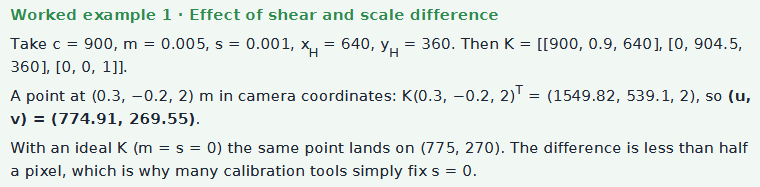

In [1]:
import numpy as np
import cv2
np.set_printoptions(suppress=True)

c,m,s =900.0, 0.005, 0.001
x_H, y_H = 640.0, 360.0
K = np.array([
    [c, c*s, x_H],
    [0, c*(1+m), y_H],
    [0, 0, 1]
])

X_c = np.array([0.3, -2.0, 2.0])
uvw = K @ X_c
print(uvw[:2]/uvw[2])

[ 774.1 -544.5]


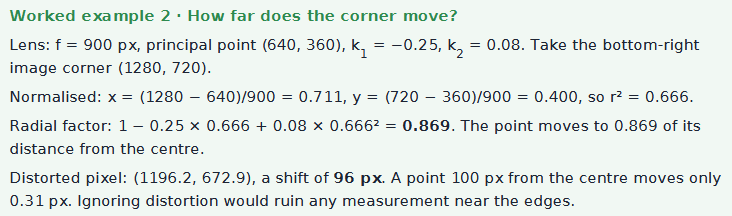

In [2]:
def distort(x,y,k1,k2,p1=0.0,p2=0.0, k3=0.0):
    r2 = x**2+y**2
    radial = 1+k1*r2+k2*r2**2+k3*r2**3
    x_d = x * radial + 2 * p1 * x * y + p2 * (r2 + 2 * x**2)
    y_d = y * radial + p1 * (r2 + 2 * y**2) + 2 * p2 * x * y
    return x_d, y_d

K = np.array([[900.0,0,640],[0,900.0,360],[0,0,1]])
dist = np.array([-0.25, 0.08, 0.0, 0.0, 0.0])

x,y = (1280-640)/900, (720-360)/900
x_d, y_d = distort(x,y, -0.25, 0.08)
print(900*x_d+640, 900*y_d+360)

# The same with OpenCV
print(cv2.projectPoints(np.array([[x, y, 1.0]]), np.zeros(3), np.zeros(3), K, dist)[0].ravel())

# And back again: undistort the distorted pixel
print(cv2.undistortPoints(np.array([[[1196.18, 672.85]]]), K, dist, P=K).ravel()) # ~[1280. 720.]
    

1196.1795396555403 672.8509910562415
[1196.17953966  672.85099106]
[1279.95788427  719.97487161]


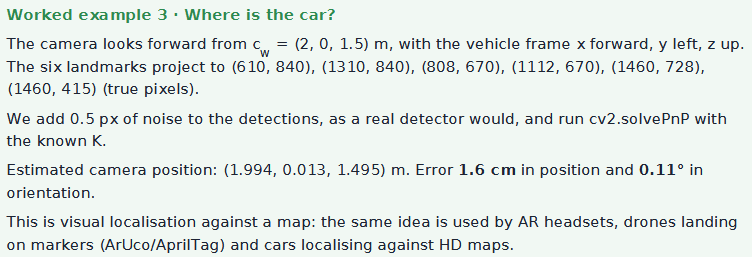

In [3]:
K_car = np.array([[2000, 0, 960], [0, 2000, 540], [0, 0, 1.0]])

X_marks = np.array([[12, 1.75, 0], [12, -1.75, 0], 
[25, 1.75, 0], [25, -1.75, 0], 
[18, -4.0, 0], [18, -4.0, 2.5]], 
dtype=float)

R_true = np.array([[0, -1, 0], [0, 0, -1], [1, 0, 0]], dtype=float)
t_true = -R_true @ np.array([2.0, 0.0, 1.5])

uv = cv2.projectPoints(X_marks, cv2.Rodrigues(R_true)[0], t_true, K_car, None)[0].reshape(-1, 2)
uv += np.random.default_rng(3).normal(0, 0.5, uv.shape)

ok, rvec, tvec = cv2.solvePnP(X_marks, uv, K_car, None)
R_est, _ = cv2.Rodrigues(rvec)
camera_position = (-R_est.T @ tvec).ravel()
print(camera_position) 

[1.99367563 0.01331371 1.49515689]


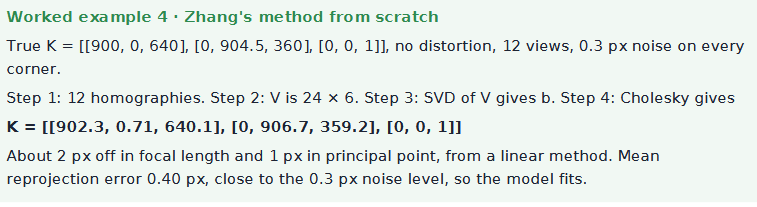

In [11]:
# Checkerboard: 9 x 6 inner corners, 25 mm squares, on the plane Z = 0
nx, ny, square = 9, 6, 0.025
obj = np.zeros((nx*ny, 3))
obj[:, :2] = np.mgrid[0:nx, 0:ny].T.reshape(-1, 2) * square

K_true = np.array([[900.0, 0, 640], [0, 904.5, 360], [0, 0, 1]])
rng = np.random.default_rng(11)
center = np.array([(nx - 1) * square / 2, (ny - 1) * square / 2, 0])

def random_view():
    angles = np.radians(rng.uniform(-35,35,3))
    angles[2] = np.radians(rng.uniform(-15,15))
    R, _ = cv2.Rodrigues(angles)
    depth = rng.uniform(0.35, 0.6)
    shift = np.array([rng.uniform(-0.08, 0.08), rng.uniform(-0.05, 0.05), depth])
    return cv2.Rodrigues(R)[0].ravel(), shift - R @ center

views = [random_view() for _ in range(15)]
noise = np.random.default_rng(5)
obs = [cv2.projectPoints(obj, rv, t, K_true, None)[0].reshape(-1, 2) + noise.normal(0, 0.3, (nx * ny, 2))
       for rv, t in views[:12]] 

def normalize2d(p):
    c = p.mean(0)
    s = np.sqrt(2) / np.mean(np.linalg.norm(p - c, axis=1))
    T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1]])
    return (T @ np.c_[p, np.ones(len(p))].T).T[:, :2], T

def homography(src, dst):
    s, Ts = normalize2d(src)
    d, Td = normalize2d(dst)
    A = []
    for (x, y), (u, v) in zip(s, d):
        A.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        A.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    _, _, Vt = np.linalg.svd(np.array(A))
    H = np.linalg.inv(Td) @ Vt[-1].reshape(3, 3) @ Ts
    return H / H[2, 2]
Hs = [homography(obj[:, :2], o) for o in obs]
    
def v_ij(H, i, j):
    h = H.T 
    return np.array([h[i, 0] * h[j, 0],
    h[i, 0] * h[j, 1] + h[i, 1] * h[j, 0],
    h[i, 1] * h[j, 1],
    h[i, 2] * h[j, 0] + h[i, 0] * h[j, 2],
    h[i, 2] * h[j, 1] + h[i, 1] * h[j, 2],
    h[i, 2] * h[j, 2]])
    
V = []
for H in Hs: 
    V.append(v_ij(H, 0, 1)) 
    V.append(v_ij(H, 0, 0) - v_ij(H, 1, 1)) 
_, _, Vt = np.linalg.svd(np.array(V))
b = Vt[-1]
B = np.array([[b[0], b[1], b[3]],
            [b[1], b[2], b[4]],
            [b[3], b[4], b[5]]])
if B[0, 0] < 0: 
    B = -B
L = np.linalg.cholesky(B) 
K_est = np.linalg.inv(L.T)
K_est /= K_est[2, 2]
print(K_est.round(1))

K_inv = np.linalg.inv(K_est)
H = Hs[0]
lam = 1 / np.linalg.norm(K_inv @ H[:, 0])
r1, r2, t = lam * K_inv @ H[:, 0], lam * K_inv @ H[:, 1], lam * K_inv @ H[:, 2]
R = np.c_[r1, r2, np.cross(r1, r2)]
U, _, Wt = np.linalg.svd(R)
R = U @ Wt 
print(t.round(3))

[[902.3   0.7 640.1]
 [  0.  906.7 359.2]
 [  0.    0.    1. ]]
[-0.043 -0.073  0.41 ]


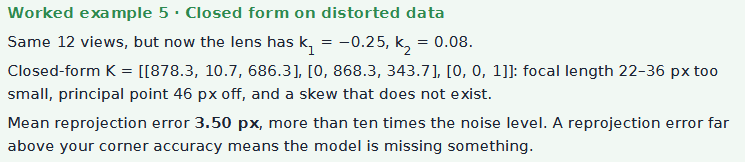

In [12]:
def zhang(observations):
    """Zhang's closed form: homographies -> V b = 0 -> Cholesky -> K, plus the pose of each view."""
    Hs = [homography(obj[:, :2], o) for o in observations]
    V = []
    for H in Hs:
        V.append(v_ij(H, 0, 1))
        V.append(v_ij(H, 0, 0) - v_ij(H, 1, 1))
    _, _, Vt = np.linalg.svd(np.array(V))
    b = Vt[-1]
    B = np.array([[b[0], b[1], b[3]],
                  [b[1], b[2], b[4]],
                  [b[3], b[4], b[5]]])
    if B[0, 0] < 0:
        B = -B
    L = np.linalg.cholesky(B)
    K = np.linalg.inv(L.T)
    K /= K[2, 2]

    K_inv = np.linalg.inv(K)
    poses = []
    for H in Hs:
        lam = 1 / np.linalg.norm(K_inv @ H[:, 0])
        r1, r2, t = lam * K_inv @ H[:, 0], lam * K_inv @ H[:, 1], lam * K_inv @ H[:, 2]
        U, _, Wt = np.linalg.svd(np.c_[r1, r2, np.cross(r1, r2)])
        poses.append((U @ Wt, t))
    return K, poses

def mean_reprojection_error(K, poses, observations, dist=None):
    errors = []
    for (R, t), o in zip(poses, observations):
        projected = cv2.projectPoints(obj, cv2.Rodrigues(R)[0], t, K, dist)[0].reshape(-1, 2)
        errors.append(np.linalg.norm(projected - o, axis=1))
    return np.concatenate(errors).mean()

# sanity check on the undistorted data from Worked example 4
K0, poses0 = zhang(obs)
print("no distortion:  K =\n", K0.round(1))
print("reprojection error:", round(mean_reprojection_error(K0, poses0, obs), 2), "px\n")

# same 12 views, but the lens now has barrel distortion
dist_true = np.array([-0.25, 0.08, 0.0, 0.0, 0.0])     # k1, k2, p1, p2, k3
noise = np.random.default_rng(5)
obs_d = [cv2.projectPoints(obj, rv, t, K_true, dist_true)[0].reshape(-1, 2)
         + noise.normal(0, 0.3, (nx * ny, 2)) for rv, t in views[:12]]

K_d, poses_d = zhang(obs_d)
print("with distortion:  K =\n", K_d.round(1))
print("reprojection error:", round(mean_reprojection_error(K_d, poses_d, obs_d), 2), "px")
print("focal error (px):", (K_d[0, 0] - K_true[0, 0]).round(1), (K_d[1, 1] - K_true[1, 1]).round(1))
print("principal point error (px):", (K_d[0, 2] - K_true[0, 2]).round(1), (K_d[1, 2] - K_true[1, 2]).round(1))

no distortion:  K =
 [[902.3   0.7 640.1]
 [  0.  906.7 359.2]
 [  0.    0.    1. ]]
reprojection error: 0.4 px

with distortion:  K =
 [[878.3  10.7 686.3]
 [  0.  868.3 343.7]
 [  0.    0.    1. ]]
reprojection error: 3.5 px
focal error (px): -21.7 -36.2
principal point error (px): 46.3 -16.3


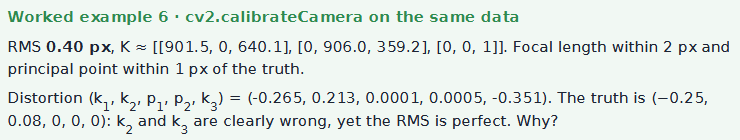

In [13]:
obj_pts = [obj.astype(np.float32)] * len(obs_d)
img_pts = [o.astype(np.float32).reshape(-1, 1, 2) for o in obs_d]

rms, K_cv, dist_cv, rvecs, tvecs = cv2.calibrateCamera(obj_pts, img_pts, (1280, 720), None, None)
np.set_printoptions(suppress=True)
print("RMS reprojection error:", round(rms, 2), "px")
print("K =\n", K_cv.round(1))
print("dist (k1, k2, p1, p2, k3) =", dist_cv.ravel().round(4))
print("true dist                 =", dist_true)

# --- Why is the RMS perfect although k2 and k3 are wrong? ---
# 1) How far from the image centre did the checkerboard corners reach (normalised radius)?
all_pts = np.vstack(obs_d)
x = (all_pts[:, 0] - K_true[0, 2]) / K_true[0, 0]
y = (all_pts[:, 1] - K_true[1, 2]) / K_true[1, 1]
r_max = np.sqrt(x**2 + y**2).max()
r_corner = np.hypot(640 / 900, 360 / 904.5)
print(f"\ncorners reach r = {r_max:.2f}; the image corner is at r = {r_corner:.2f}")

# 2) Compare the radial factor 1 + k1 r^2 + k2 r^4 + k3 r^6 of the true lens and of the fit
def radial(r, d):
    k1, k2, k3 = d[0], d[1], d[4]
    return 1 + k1 * r**2 + k2 * r**4 + k3 * r**6

for r in [0.2, 0.4, r_max, 0.6, 0.7, r_corner]:
    t, f = radial(r, dist_true), radial(r, dist_cv.ravel())
    shift_px = (f - t) * r * 900                    # difference in pixels at that radius
    print(f"r = {r:.2f}:  true {t:.4f}  fitted {f:.4f}  -> {shift_px:+6.2f} px")

RMS reprojection error: 0.4 px
K =
 [[901.5   0.  640.1]
 [  0.  906.  359.2]
 [  0.    0.    1. ]]
dist (k1, k2, p1, p2, k3) = [-0.265   0.2133  0.0001  0.0005 -0.351 ]
true dist                 = [-0.25  0.08  0.    0.    0.  ]

corners reach r = 0.47; the image corner is at r = 0.81
r = 0.20:  true 0.9901  fitted 0.9897  ->  -0.07 px
r = 0.40:  true 0.9620  fitted 0.9616  ->  -0.15 px
r = 0.47:  true 0.9493  fitted 0.9487  ->  -0.24 px
r = 0.60:  true 0.9204  fitted 0.9159  ->  -2.43 px
r = 0.70:  true 0.8967  fitted 0.8801  -> -10.48 px
r = 0.81:  true 0.8693  fitted 0.8153  -> -39.57 px


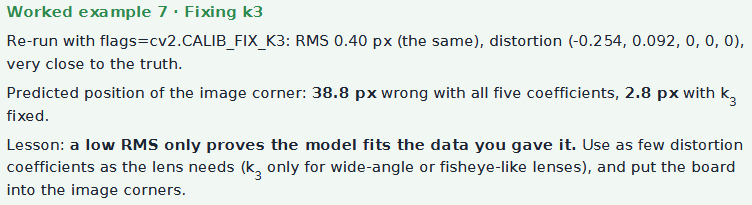

In [14]:
rms3, K_cv3, dist_cv3, _, _ = cv2.calibrateCamera(obj_pts, img_pts, (1280, 720), None, None,
                                                  flags=cv2.CALIB_FIX_K3)
print("RMS with all 5 coefficients:", round(rms, 2), "px")
print("RMS with k3 fixed to 0     :", round(rms3, 2), "px")
print("dist, 5 coefficients:", dist_cv.ravel().round(3))
print("dist, k3 fixed      :", dist_cv3.ravel().round(3))
print("true dist           :", dist_true)

# Where does each model put the bottom-right image corner?
# The ray that SHOULD land on pixel (1280, 720), as a normalised camera-frame point:
corner_ray = np.array([[640 / 900, 360 / 904.5, 1.0]])

def project(dist):
    """Project the corner ray with the true K and a given set of distortion coefficients."""
    return cv2.projectPoints(corner_ray, np.zeros(3), np.zeros(3), K_true, dist)[0].ravel()

p_true = project(dist_true)
p_5 = project(dist_cv.ravel())
p_3 = project(dist_cv3.ravel())
print("\ncorner with true lens  :", p_true.round(1))
print("corner, 5 coefficients :", p_5.round(1), f"-> {np.linalg.norm(p_5 - p_true):.1f} px wrong")
print("corner, k3 fixed       :", p_3.round(1), f"-> {np.linalg.norm(p_3 - p_true):.1f} px wrong")

RMS with all 5 coefficients: 0.4 px
RMS with k3 fixed to 0     : 0.4 px
dist, 5 coefficients: [-0.265  0.213  0.     0.001 -0.351]
dist, k3 fixed      : [-0.254  0.092  0.     0.     0.   ]
true dist           : [-0.25  0.08  0.    0.    0.  ]

corner with true lens  : [1196.3  672.9]
corner, 5 coefficients : [1162.6  653.8] -> 38.8 px wrong
corner, k3 fixed       : [1198.8  674.2] -> 2.8 px wrong
